# The discount factor as a markup

`planner_consumption_deviation.ipynb` and the rest of the planner family treat the
time-to-produce discount $\beta^{\tau_i}$ as part of firm $i$'s **technology**: it is folded
into `tprod`, the CES aggregate of `tprod` is called measured TFP $\tilde A$, natural output
is $\varphi_{ya}\tilde a$, and the discount content $d=\log(\tilde A/Z)$ is subtracted from
output at the end to recover a "physical" path.

This notebook takes the other reading, which is the one the firm's problem actually implies.
The firm produces at $t$ and is paid at $t+\tau_i$, so it solves

$$\max_{p_i}\ \ \text{disc}_i\, p_i c_i - W n_i,\qquad n_i=\frac{c_i}{Z_i sm_i},
\qquad c_i=(p_i/P)^{-\sigma}C$$

whose first-order condition is

$$p_i=\underbrace{\frac{\sigma}{\sigma-1}}_{\text{markup}}\cdot
   \underbrace{\frac{1}{\text{disc}_i}}_{\textbf{also a markup}}\cdot\frac{W}{Z_i sm_i}.$$

$1/\text{disc}_i$ is a firm-specific **markup wedge**. It multiplies the price; it does not
enter the production function $c_i=Z_i sm_i n_i$ at all.

**Why this matters.** Technology and markups enter the natural level of output with
different coefficients,

$$y^n=\frac{1+\eta}{\gamma+\eta}\,a-\frac{1}{\gamma+\eta}\log\mu,$$

so $\varphi_{ya}=3/4$ on technology but $-1/4$ on the wedge. Folding the discount into $a$
applies $3/4$ to it, and the closing $y-d$ step then leaves a net $-1/4$ — the right
magnitude with the **wrong sign**. Section 3 shows that against a flex-price equilibrium
solved directly from the primitives: the error is invisible when the rate is flat (because
then $d\approx0$) and reaches $1.2$pp once policy moves the rate, on a shock that moves
potential by $1.08$pp.

Two further changes come along with it:

* **There is no $y-d$ step.** Output from the Euler equation is already real consumption.
  The wedge goes into $y^n$ with coefficient $1/(\gamma+\eta)$ and stays there.
* **The price index is the Dixit–Stiglitz one.** The planner family uses
  `A_price = [sum tprod^-(s-1)]^(1/(s-1))`, which has both exponents flipped relative to
  $P=[\sum p^{1-\sigma}]^{1/(1-\sigma)}$. Since $p_i\propto1/\text{tprod}_i$ the correct
  index is exactly $1/\tilde A$ — an object the old code already computed. That is an
  independent fix and is applied here too.

Everything else — calibration, the staggering matrix, the preference-shock reading of the
demand shock, the planner's escalation over the free horizon $L$ — is unchanged.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

/Users/samuelzhao/anaconda3/lib/python3.10/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


## 1. Calibration

Identical to the other `semi_endo` notebooks.

In [2]:
sigma = 5
beta = 1 / (1.0 + 0.01)
beta1 = 1 / (1.0 + 0.01 * np.exp(30 / (36.5 * 0.9)))
beta_hh = beta
rho = 1 / beta_hh - 1

gamma = 2.0
eta = 2.0
PHI_YA = (1 + eta) / (gamma + eta)      # coefficient on TECHNOLOGY
PHI_MU = 1.0 / (gamma + eta)            # coefficient on the MARKUP wedge
chi = 1.0
mu = sigma / (sigma - 1)

A_SHOCK = 0.97                 # 3 per cent TFP decline
D_SHOCK = 0.01                 # 1 per cent demand shock
T = 30

print(f'gamma={gamma}, eta={eta}, phi_ya={PHI_YA:.4f}, phi_mu={PHI_MU:.4f}, rho={rho:.6f}')
print(f'markup sigma/(sigma-1) = {mu:.4f}')
print(f'A shock = {A_SHOCK} ({100*(1-A_SHOCK):.0f}%),  demand shock = {100*D_SHOCK:.0f}%')

gamma=2.0, eta=2.0, phi_ya=0.7500, phi_mu=0.2500, rho=0.010000
markup sigma/(sigma-1) = 1.2500
A shock = 0.97 (3%),  demand shock = 1%


In [3]:
data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)
data_tau = data['invtCogsRatio'] * 36.5 / (30 * 0.1)

c_list = np.linspace(0, 0.99, 1000)
tau_diff = np.zeros(1000)
for i, cv in enumerate(c_list):
    if beta * cv <= 1e-10:
        tau_diff[i] = np.inf
        continue
    Nn = -(data_tau) - 1 / np.log(beta * cv)
    t1 = -1 / np.log(beta * cv) - Nn;  t1[t1 < 0] = 0
    t2 = -1 / np.log(beta1 * cv) - Nn; t2[t2 < 0] = 0
    tau_diff[i] = np.mean(np.abs(t1 - t2))
c = np.min(c_list[np.where(np.abs(tau_diff - 1) == np.min(np.abs(tau_diff - 1)))[0]])

N = -data_tau - 1 / np.log(beta * c)
tau = -1 / np.log(beta * c) - N
tau[tau < 0] = 0
tf, tc = np.floor(tau), np.ceil(tau)
pc = (beta * c)**tc * (tc + N)
pf = (beta * c)**tf * (tf + N)
tau[(pc - pf) > 0] = tc[(pc - pf) > 0]
tau[(pc - pf) < 0] = tf[(pc - pf) < 0]
tau[tau < 0] = 0

tvals = tau.astype(int).to_numpy()
N_array = np.array(N)
NFIRMS = len(tvals)
Z_PHYS = c * (tvals + N_array)          # physical output per unit labour, no discount
print(f'c = {c:.7f}   mean tau = {tau.mean():.4f}   firms = {NFIRMS}')

/var/folders/26/bmvk0hrd5xbgcvl_s6s42rf80000gn/T/ipykernel_92847/2367552699.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data = pd.read_csv('APP_data_usa_goods.csv', index_col=0, parse_dates=True)


c = 0.9018018   mean tau = 2.8885   firms = 269


In [4]:
def generate_pattern_array_with_extra_rows(tau, shock=A_SHOCK):
    """Staggering matrix: which firms have re-optimised by period t."""
    tau = np.asarray(tau)
    n = len(tau) + int(np.min(tau))
    m = int(np.max(tau)) + int(np.min(tau))
    missing = len(set(range(int(max(tau)) + 1)) - set(tau))
    A = np.ones((m + 2, n + missing), dtype=float)
    count = 0
    for i in range(1, m + 2):
        firms = tau[tau == i - 1]
        for j in range(len(firms)):
            A[i, n - i - j - count] = shock
        if len(firms) > 1:
            count += len(firms) - 1
    return np.vstack([A, np.ones(n + missing)])[:, 0:n - int(np.min(tau))]


A_PATTERN = generate_pattern_array_with_extra_rows(tau)
print('staggering matrix:', A_PATTERN.shape,
      f'-> shock fully worked through by t = {A_PATTERN.shape[0] - 1}')

staggering matrix: (16, 269) -> shock fully worked through by t = 15


## 2. The model

The aggregation is worked out once here so the code below is a transcription rather than an
assertion.

With $p_i=\mu W/(\text{disc}_i Z_i sm_i)$ the price index is

$$P=\Big[\textstyle\sum_i p_i^{1-\sigma}\Big]^{\frac1{1-\sigma}}
   =\frac{\mu W}{\tilde A},\qquad
   \tilde A\equiv\Big[\textstyle\sum_i(\text{disc}_i Z_i sm_i)^{\sigma-1}\Big]^{\frac1{\sigma-1}}$$

so $\tilde A$ is not TFP — it is the real wage times the markup, $W/P=\tilde A/\mu$.

True aggregate physical productivity comes from the firm-level allocation. Using
$c_i=(p_i/P)^{-\sigma}C$ and $n_i=c_i/(Z_i sm_i)$,

$$\Lambda\equiv\frac{C}{N}=\frac{\tilde A^{\sigma}}{\Omega},\qquad
  \Omega\equiv\sum_i \text{disc}_i^{\sigma}\,(Z_i sm_i)^{\sigma-1}$$

When every firm shares the same discount factor $\delta$ this collapses to
$Z\equiv[\sum_i(Z_i sm_i)^{\sigma-1}]^{1/(\sigma-1)}$ exactly, so the whole gap between
$\Lambda$ and $Z$ is relative-price dispersion across heterogeneous $\tau_i$.

$Z$ is also the **first best**: a planner allocating labour directly to maximise the CES
aggregate sets $n_i\propto Z_i^{\sigma-1}$, which gives $C/N=Z$ exactly. So
$\Lambda\le Z$ always, with equality iff dispersion is zero — section 8 confirms this
numerically and shows $\Lambda\to Z$ as $i\to0$. The efficient benchmark is therefore
$y^e=\varphi_{ya}\log Z$, which does **not** move with policy, while welfare must use the
actual $\Lambda$ because labour really is $C/\Lambda$. Conflating the two lets the planner
manipulate its own benchmark.

The aggregate wedge is $d\equiv\log\tilde A-\log\Lambda=-\log\mu_{\text{extra}}$, giving

$$y^n=\varphi_{ya}\,a^{\text{phys}}+\frac{d}{\gamma+\eta},\qquad
  y^e=\varphi_{ya}\,\log Z,\qquad y=x+y^n$$

and $y$ is real consumption directly — $C=e^{y}$, $N=e^{y-a^{\text{phys}}}$.

`phys_exact=False` replaces $\Lambda$ by $Z$ throughout, which switches the dispersion
channel off. **Sections 5–7 use it**, so that the markup-vs-technology question is isolated
from the Friedman-rule motive that dispersion introduces; section 8 turns it back on.

**One convention carried over from the rest of the repo:** the nominal wage is the
numeraire, $W\equiv1$, so $\pi_t=-\Delta\log\tilde A_t$. There is no separate wage block in
any of these notebooks; inflation is entirely the movement in firms' desired markups over a
fixed wage.

In [5]:
def shock_matrix(T, on, shock_ttb=True):
    """TFP shock pattern.  shock_ttb=False hits every firm at t=0 at once."""
    ps = np.ones((T, NFIRMS))
    if on:
        if shock_ttb:
            ps[0:15] = A_PATTERN[1:]
        else:
            ps[0, :] = A_SHOCK
    return ps


def disc_matrix(r, T, time_to_build=True):
    """Cumulative discount over tau_i periods, implied by the rate path r."""
    L = len(r)
    irl = np.ones((T, T)) * rho
    blk = np.full((L, L), rho, dtype=float)
    for i in range(L):
        blk[i, :i + 1] = np.asarray(r, float)[i::-1]
    irl[0:L, :L] = blk
    ce = np.ones((T, T + 1))
    ce[:, 1:] = np.cumprod(1.0 / (1.0 + irl), axis=1)
    tv = tvals if time_to_build else np.zeros_like(tvals)
    return ce[:, tv]


def pref_shifter(dem):
    """Log preference shifter z_t: dem_t = z_{t+1} - z_t, normalised to z_T = 0."""
    dem = np.asarray(dem, float)
    return -np.cumsum(dem[::-1])[::-1]


def solve(r, T=T, a_shock=False, demand=None, time_to_build=True, shock_ttb=None,
          phys_exact=True, ds_price=True, legacy=False):
    """The model with the discount treated as a MARKUP.

    legacy=True reproduces the planner family's treatment instead (discount folded into
    technology, closing y - d step, flipped price index) so the two can be compared inside
    one pipeline.  It is used only in section 4.
    """
    if shock_ttb is None:
        shock_ttb = time_to_build
    sm = shock_matrix(T, a_shock, shock_ttb)
    disc = disc_matrix(r, T, time_to_build)
    ZS = Z_PHYS * sm
    tprod = disc * ZS

    A_til = np.sum(tprod**(sigma - 1), axis=1)**(1 / (sigma - 1))   # = mu * W / P
    Omega = np.sum(disc**sigma * ZS**(sigma - 1), axis=1)
    Lam = A_til**sigma / Omega                                      # true C/N
    Z_t = np.sum(ZS**(sigma - 1), axis=1)**(1 / (sigma - 1))        # dispersion-free

    phys = Lam if phys_exact else Z_t
    a_phys = np.log(phys) - np.log(phys)[-1]        # ACTUAL technology: N = C/Lam
    d = np.log(A_til) - np.log(phys); d = d - d[-1]                 # -log(markup wedge)
    # First best.  Allocating labour to maximise the CES aggregate gives n_i prop Z_i^(s-1)
    # and hence C/N = Z_t exactly, so Z_t -- not Lam -- is the efficient benchmark, and it
    # does not move with policy.  Lam <= Z_t always, with equality iff dispersion is zero.
    a_eff = np.log(Z_t) - np.log(Z_t)[-1]

    if ds_price:
        price_level = -np.log(A_til)          # P = mu W / A_til, W numeraire
    else:
        price_level = np.log(np.sum(1 / tprod**(sigma - 1), axis=1)**(1 / (sigma - 1)))
    pi = np.zeros(T); pi[1:] = price_level[1:] - price_level[:-1]
    pi_fwd = np.r_[pi[1:], 0.0]

    if legacy:
        a_nat = np.log(A_til) - np.log(A_til)[-1]
        y_nat = PHI_YA * a_nat
    else:
        y_nat = PHI_YA * a_phys + PHI_MU * d

    dy = np.r_[y_nat[1:] - y_nat[:-1], 0.0]
    ip = np.ones(T) * rho; ip[:len(r)] = r
    dem = np.zeros(T) if demand is None else np.asarray(demand, float)
    r_nat = rho - dem + gamma * dy

    x = np.zeros(T + 1)
    for t in range(T - 1, -1, -1):
        x[t] = x[t + 1] - (1.0 / gamma) * (ip[t] - pi_fwd[t] - r_nat[t])
    x = x[:T]
    y = x + y_nat

    y_real = y - d if legacy else y            # legacy strips the discount; we do not
    return dict(y=y_real, x=x, i=ip, pi=pi, d=d, y_nat=y_nat, r_nat=r_nat,
                a_phys=a_phys, a_eff=a_eff, y_eff=PHI_YA * a_eff,
                Lam=Lam, Z_t=Z_t, A_til=A_til,
                zeta=pref_shifter(dem))


def welfare(s):
    """Discounted utility.  y is already real consumption, so C = e^y directly."""
    y, a = s['y'], s['a_phys']
    disc = beta_hh ** np.arange(len(y)) * np.exp(s['zeta'])
    C = np.exp(y)
    Nl = np.exp(y - a)
    uc = C**(1 - gamma) / (1 - gamma)
    un = chi * Nl**(1 + eta) / (1 + eta)
    return float(np.sum(disc * (uc - un))), float(np.sum(disc * uc)), float(np.sum(disc * un))


def cons_equivalent(U_alt, UC_base, UN_base):
    return ((U_alt + UN_base) / UC_base)**(1.0 / (1.0 - gamma)) - 1.0


CASES = {'TFP shock (3%)':    dict(a_shock=True,  demand=None),
         'Demand shock (1%)': dict(a_shock=False,
                                   demand=np.r_[D_SHOCK, np.zeros(T - 1)])}
print('cases:', list(CASES))

cases: ['TFP shock (3%)', 'Demand shock (1%)']


## 3. Validation against the primitives

Nothing above should be taken on trust. This cell solves the flex-price equilibrium
**directly** — firm FOC gives $p_i$, CES demand gives $c_i$, $n_i=c_i/(Z_i sm_i)$, and the
labour-supply condition $W/P=\chi N^{\eta}C^{\gamma}$ closes it — and then rebuilds $C$ and
$N$ from the firm-level allocations as a consistency check before comparing the two
aggregate formulas against it.

The comparison is run over four rate paths, because that is where the two treatments
separate: the wedge $d$ is near zero when the rate is flat, so a sign error on it is
invisible until policy starts moving.

In [6]:
def flex_price_equilibrium(r, a_shock=False, time_to_build=True):
    """Solve the flex-price equilibrium from primitives, with no aggregation shortcuts."""
    sm = shock_matrix(T, a_shock, time_to_build)
    disc = disc_matrix(r, T, time_to_build)
    ZS = Z_PHYS * sm
    price = mu * 1.0 / (disc * ZS)                      # firm FOC, W = 1
    P = np.sum(price**(1 - sigma), axis=1)**(1 / (1 - sigma))
    A_til = np.sum((disc * ZS)**(sigma - 1), axis=1)**(1 / (sigma - 1))
    Lam = A_til**sigma / np.sum(disc**sigma * ZS**(sigma - 1), axis=1)
    # W/P = A_til/mu  and  W/P = chi N^eta C^gamma  with  C = Lam * N
    Nn = (A_til / (mu * chi))**(1 / (gamma + eta)) * Lam**(-gamma / (gamma + eta))
    Cc = Lam * Nn
    # rebuild from firm level
    c_i = (price / P[:, None])**(-sigma) * Cc[:, None]
    C_ces = np.sum(c_i**((sigma - 1) / sigma), axis=1)**(sigma / (sigma - 1))
    N_sum = np.sum(c_i / ZS, axis=1)
    return dict(C=Cc, N=Nn, P=P, Lam=Lam, A_til=A_til,
                chk_C=float(np.max(np.abs(np.log(C_ces / Cc)))),
                chk_N=float(np.max(np.abs(np.log(N_sum / Nn)))))


def dev(v):
    return np.log(v) - np.log(v)[-1]


PATHS = {'flat at rho':              np.ones(8) * rho,
         'flat at rho + 50bp':       np.ones(8) * (rho + 0.005),
         'planner-like oscillation': np.array([.0169, .0036, .0144, .0075, .0119, .0106, .01, .01]),
         'aggressive cut':           np.array([0., 0., 0., .005, .01, .01, .01, .01])}

print('TFP shock, natural output: error vs the equilibrium solved from primitives\n')
print(f'{"rate path":<26}{"max|d|":>10}{"legacy  phi*a_nat - d":>24}{"markup  phi*a_phys + d/(g+e)":>31}')
print('-' * 91)
for lab, R in PATHS.items():
    eq = flex_price_equilibrium(R, a_shock=True)
    assert eq['chk_C'] < 1e-12 and eq['chk_N'] < 1e-12, 'firm-level rebuild failed'
    y_true = dev(eq['C'])
    A_til, Lam = eq['A_til'], eq['Lam']
    d = dev(A_til) - dev(Lam)
    y_legacy = PHI_YA * dev(A_til) - d
    y_markup = PHI_YA * dev(Lam) + PHI_MU * d
    print(f'{lab:<26}{100*np.max(np.abs(d)):>9.4f}p{100*np.max(np.abs(y_legacy-y_true)):>23.4f}'
          f'{100*np.max(np.abs(y_markup-y_true)):>31.4f}')

print('\n(all figures in percentage points; firm-level rebuild consistent to <1e-12 throughout)')

eq = flex_price_equilibrium(PATHS['aggressive cut'], a_shock=True)
d = dev(eq['A_til']) - dev(eq['Lam'])
print('\nthe sign error, made concrete -- aggressive cut, TFP shock, t = 0..4 (pp):')
print(f'   {"direct from primitives":<26}{np.round(100*dev(eq["C"])[:5], 4)}')
print(f'   {"legacy":<26}{np.round(100*(PHI_YA*dev(eq["A_til"]) - d)[:5], 4)}')
print(f'   {"markup":<26}{np.round(100*(PHI_YA*dev(eq["Lam"]) + PHI_MU*d)[:5], 4)}')
print('   -> legacy has the wrong SIGN at t=0, not merely the wrong size.')

print('\nexact Lambda vs dispersion-free Z (the phys_exact switch):')
for lab, R in PATHS.items():
    eqx = flex_price_equilibrium(R, a_shock=True)
    s = solve(R, a_shock=True, phys_exact=False)
    print(f'   {lab:<26} max|log(Lambda) - log(Z)| = '
          f'{100*np.max(np.abs(dev(eqx["Lam"]) - dev(s["Z_t"]))):.5f} pp')

TFP shock, natural output: error vs the equilibrium solved from primitives

rate path                     max|d|   legacy  phi*a_nat - d   markup  phi*a_phys + d/(g+e)
-------------------------------------------------------------------------------------------
flat at rho                  0.0321p                 0.0160                         0.0000
flat at rho + 50bp           1.3367p                 0.6683                         0.0000
planner-like oscillation     0.6754p                 0.3377                         0.0000
aggressive cut               2.3645p                 1.1823                         0.0000

(all figures in percentage points; firm-level rebuild consistent to <1e-12 throughout)

the sign error, made concrete -- aggressive cut, TFP shock, t = 0..4 (pp):
   direct from primitives    [ 0.2413  0.2285 -0.2008  0.0631 -0.0586]
   legacy                    [-0.2558 -0.717  -1.383  -1.001  -0.7008]
   markup                    [ 0.2413  0.2285 -0.2008  0.0631 -0.0586]

## 4. Side by side with the legacy treatment

`legacy=True` runs the planner family's version through the same pipeline. The price index
is reported separately, since that fix is independent of the markup question and applies to
either treatment.

In [7]:
R = np.ones(8) * (rho + 0.005)
for name, kw in CASES.items():
    s_new = solve(R, **kw)
    s_old = solve(R, legacy=True, ds_price=False, **kw)
    s_mid = solve(R, legacy=True, ds_price=True, **kw)
    print(f'{name}   (+50bp held 8 periods)')
    print(f'   {"t":<28}' + ''.join(f'{t:>10}' for t in range(6)))
    for lab, v in [('legacy, old price index', s_old['y']),
                   ('legacy, DS price index', s_mid['y']),
                   ('markup treatment', s_new['y'])]:
        print(f'   {lab:<28}' + ''.join(f'{100*v[t]:>10.4f}' for t in range(6)))
    print(f'   {"wedge d":<28}' + ''.join(f'{100*s_new["d"][t]:>10.4f}' for t in range(6)))
    print()

print('inflation, TFP shock, the two price indices (pp):')
s_ds = solve(R, a_shock=True, ds_price=True)
s_ol = solve(R, a_shock=True, ds_price=False)
print(f'   {"Dixit-Stiglitz  -log(A_til)":<30}{np.round(100*s_ds["pi"][:6], 4)}')
print(f'   {"legacy A_price":<30}{np.round(100*s_ol["pi"][:6], 4)}')

TFP shock (3%)   (+50bp held 8 periods)
   t                                    0         1         2         3         4         5
   legacy, old price index        -1.7655   -1.5323   -1.5503   -1.0253   -0.6090   -0.2209
   legacy, DS price index         -1.7606   -1.4772   -1.4934   -0.9530   -0.6293   -0.1961
   markup treatment               -2.2497   -2.3636   -2.6111   -2.2476   -1.9660   -1.5307
   wedge d                        -0.4891   -0.8865   -1.1177   -1.2946   -1.3367   -1.3346

Demand shock (1%)   (+50bp held 8 periods)
   t                                    0         1         2         3         4         5
   legacy, old price index        -2.2540   -1.2949   -0.9373   -0.6436   -0.3864   -0.1387
   legacy, DS price index         -2.2542   -1.2937   -0.9324   -0.6325   -0.3698   -0.1182
   markup treatment               -2.7461   -2.2129   -2.0896   -1.9045   -1.6758   -1.4314
   wedge d                        -0.4919   -0.9193   -1.1572   -1.2720   -1.3060   -1.3

## 5. Is the problem interior?

Sections 5–7 run with `phys_exact=False`, i.e. with markup *dispersion* switched off, so
that what is measured here is the effect of the markup reclassification alone. Section 8
adds dispersion back.

The diagnostic from the planner family. There it was the discount adjustment that made the
problem interior; the question is whether the markup treatment does so on its own, without
any adjustment step.

In [8]:
grid = np.array([0.0, 0.0025, 0.005, 0.0075, rho, 0.0125, 0.015, 0.02])
for name, kw in CASES.items():
    u = np.array([welfare(solve(np.ones(8) * lv, phys_exact=False, **kw))[0] for lv in grid])
    i_max = int(np.argmax(u))
    print(f'\n{name}')
    print(f'{"uniform i":>10} {"U (markup)":>20}')
    print('-' * 40)
    for k, lv in enumerate(grid):
        print(f'{lv:>10.4f} {u[k]:>20.9f} {"<- max" if k == i_max else ""}')
    print(f'   argmax at i = {grid[i_max]:.4f}, interior = {i_max not in (0, len(grid) - 1)}, '
          f'monotone = {bool(np.all(np.diff(u) < 0) or np.all(np.diff(u) > 0))}')


TFP shock (3%)
 uniform i           U (markup)
----------------------------------------
    0.0000        -34.804201129 
    0.0025        -34.794875703 
    0.0050        -34.788218411 
    0.0075        -34.784161706 
    0.0100        -34.782640549 <- max
    0.0125        -34.783592319 
    0.0150        -34.786956724 
    0.0200        -34.800693434 
   argmax at i = 0.0100, interior = True, monotone = False

Demand shock (1%)
 uniform i           U (markup)
----------------------------------------
    0.0000        -34.760533059 
    0.0025        -34.751795343 
    0.0050        -34.745698448 
    0.0075        -34.742175688 
    0.0100        -34.741162855 <- max
    0.0125        -34.742598127 
    0.0150        -34.746421989 
    0.0200        -34.761008441 
   argmax at i = 0.0100, interior = True, monotone = False


## 6. The planner's problem

Same escalation as the planner family: grow the free horizon $L$, judge convergence on the
objective rather than on the tail of the rate path, solve each $L$ from several starting
points, and report every horizon that attains the best value.

In [9]:
SEEDS = [lambda L: np.ones(L) * rho,
         lambda L: np.linspace(0.005, 0.015, L),
         lambda L: np.full(L, 0.005)]


def escalate(kw, L_range=range(1, 15), bounds=(0.0, 0.05), tol=1e-9, verbose=True, **skw):
    def obj(r):
        return -welfare(solve(r, **kw, **skw))[0]

    hist = {}
    if verbose:
        print(f'{"L":>3} {"objective":>20} {"peak |y-y_eff|":>16} {"last i":>9}   sequence')
        print('-' * 96)
    for L in L_range:
        best = None
        for seed in SEEDS:
            res = minimize(obj, seed(L), method='L-BFGS-B', bounds=[bounds] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s = solve(best.x, **kw, **skw)
        hist[L] = (best.x.copy(), float(best.fun), s)
        if verbose:
            print(f'{L:>3} {best.fun:>20.12f} '
                  f'{np.max(np.abs(s["y"] - s["y_eff"])):>16.3e} {best.x[-1]:>9.5f}   '
                  f'{np.round(best.x[:6], 5)}{" ..." if L > 6 else ""}')
    bestval = min(v[1] for v in hist.values())
    attain = [L for L, v in hist.items() if v[1] - bestval < tol]
    L_conv = min(attain)
    if verbose:
        print(f'\n-> best objective {bestval:.12f}, first reached at L = {L_conv}')
        print(f'   horizons attaining it: {attain}')
        worse = [L for L in hist if L > L_conv and L not in attain]
        if worse:
            print(f'   larger horizons that score WORSE (local optima): {worse}')
    return hist, L_conv


results = {}
for name, kw in CASES.items():
    print('=' * 96); print(name); print('=' * 96)
    results[name] = escalate(kw, phys_exact=False)
    print()

TFP shock (3%)
  L            objective   peak |y-y_eff|    last i   sequence
------------------------------------------------------------------------------------------------


  1      34.782640544729        2.822e-03   0.01005   [0.01005]
  2      34.782638500279        2.822e-03   0.01128   [0.0094  0.01128]
  3      34.782622726098        1.563e-03   0.01319   [0.00838 0.01013 0.01319]


  4      34.782617956440        1.260e-03   0.01049   [0.00827 0.01001 0.01302 0.01049]


  5      34.782614888842        3.749e-04   0.01044   [0.00821 0.00994 0.01292 0.01034 0.01044]


  6      34.782614621021        5.212e-05   0.00964   [0.00824 0.00998 0.01297 0.01042 0.01057 0.00964]


...

 10      34.741113516333        1.016e-07   0.00998   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 11      34.741113516333        1.204e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 12      34.741113516333        1.549e-07   0.01000   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 13      34.741113516333        1.267e-07   0.01001   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...


 14      34.741113516333        1.392e-07   0.00999   [0.0034  0.01268 0.01063 0.01003 0.00974 0.00992] ...

-> best objective 34.741113516333, first reached at L = 1
   horizons attaining it: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]



In [10]:
w = 44
summary = {}
for name, kw in CASES.items():
    hist, L_conv = results[name]
    r_opt, f_opt, s_opt = hist[L_conv]
    s_base = solve(np.ones(3) * rho, phys_exact=False, **kw)
    U_b, UC_b, UN_b = welfare(s_base)
    U_o = welfare(s_opt)[0]
    summary[name] = (r_opt, s_opt, s_base)
    print('=' * 78); print(name); print('=' * 78)
    print(f'{"free periods needed":<{w}}: {L_conv}')
    print(f'{"utility, no policy change":<{w}}: {U_b:.10f}')
    print(f'{"utility, planner":<{w}}: {U_o:.10f}')
    print(f'{"welfare gain (consumption equivalent)":<{w}}: '
          f'{100 * cons_equivalent(U_o, UC_b, UN_b):+.6f}% of ss C')
    print(f'{"peak |y-y_eff|, no policy change":<{w}}: '
          f'{np.max(np.abs(s_base["y"] - s_base["y_eff"])):.4e}')
    print(f'{"peak |y-y_eff|, planner":<{w}}: '
          f'{np.max(np.abs(s_opt["y"] - s_opt["y_eff"])):.4e}')
    print(f'{"optimum on a bound of [0, 0.05]":<{w}}: '
          f'{bool(np.any(np.isclose(r_opt, 0.0) | np.isclose(r_opt, 0.05)))}')
    print(f'{"optimal rate path":<{w}}: {np.round(r_opt[:8], 5)}')
    print(f'{"sign of successive changes in i":<{w}}: '
          f'{np.sign(np.diff(r_opt[:8])).astype(int)}')
    print(f'{"physical TFP trough a_phys":<{w}}: {s_opt["a_phys"].min():.6f}')
    print()

TFP shock (3%)
free periods needed                         : 11
utility, no policy change                   : -34.7826405488
utility, planner                            : -34.7826146093
welfare gain (consumption equivalent)       : +0.000099% of ss C
peak |y-y_eff|, no policy change            : 2.8224e-03
peak |y-y_eff|, planner                     : 1.6265e-05
optimum on a bound of [0, 0.05]             : False
optimal rate path                           : [0.00825 0.00998 0.01298 0.01043 0.01059 0.00968 0.00978 0.01009]
sign of successive changes in i             : [ 1  1 -1  1 -1  1  1]
physical TFP trough a_phys                  : -0.010803

Demand shock (1%)
free periods needed                         : 1
utility, no policy change                   : -34.7411628545
utility, planner                            : -34.7411135163
welfare gain (consumption equivalent)       : +0.000189% of ss C
peak |y-y_eff|, no policy change            : 5.0000e-03
peak |y-y_eff|, planner            

### Steady-state check

`solve` normalises to the terminal date of the path being evaluated. Since the rate returns
to $\rho$ and both shocks die out, that terminal point is the fixed-rate no-shock steady
state, so $y_t=\log(C_t/C_{ss})$ against a single fixed benchmark. Checked rather than
assumed.

In [11]:
chk = solve(np.ones(3) * rho, a_shock=False, demand=None, phys_exact=False)
print('no shock, i fixed at rho:')
print(f'   max |c_t|  = {np.max(np.abs(chk["y"])):.3e}')
print(f'   max |n_t|  = {np.max(np.abs(chk["y"] - chk["a_phys"])):.3e}')
print(f'   max |d_t|  = {np.max(np.abs(chk["d"])):.3e}')
print('   -> C_ss = N_ss = 1 exactly; this is the benchmark.\n')

print('shocked paths return to it:')
for name in CASES:
    _, s_opt, s_base = summary[name]
    print(f'   {name:<20} |c_T| base = {abs(s_base["y"][-1]):.3e}   '
          f'planner = {abs(s_opt["y"][-1]):.3e}')

print('\nconsumption trough, per cent of steady state:')
print(f'{"":<22}{"rate fixed":>13}{"planner":>12}{"efficient":>12}')
print('-' * 59)
for name in CASES:
    _, s_opt, s_base = summary[name]
    cb = 100 * (np.exp(s_base['y']) - 1)
    cp = 100 * (np.exp(s_opt['y']) - 1)
    ce = 100 * (np.exp(s_opt['y_eff']) - 1)
    j = int(np.argmax(np.abs(cb)))
    print(f'{name:<22}{cb[j]:>12.4f}%{cp[j]:>11.4f}%{ce[j]:>11.4f}%')

no shock, i fixed at rho:
   max |c_t|  = 0.000e+00
   max |n_t|  = 0.000e+00
   max |d_t|  = 0.000e+00
   -> C_ss = N_ss = 1 exactly; this is the benchmark.

shocked paths return to it:
   TFP shock (3%)       |c_T| base = 0.000e+00   planner = 0.000e+00
   Demand shock (1%)    |c_T| base = 0.000e+00   planner = 0.000e+00

consumption trough, per cent of steady state:
                         rate fixed     planner   efficient
-----------------------------------------------------------
TFP shock (3%)             -0.5266%    -0.8069%    -0.8069%
Demand shock (1%)          -0.4988%    -0.0000%     0.0000%


### What the gap is made of

$$x_t=y_t-y^n_t\quad\text{(against the natural level)}\qquad
  y_t-y^e_t\quad\text{(against the efficient level)}$$

They differ by the wedge $y^n-y^e=d/(\gamma+\eta)$, which is what time-to-produce adds to
the textbook model. Under the legacy treatment that term carried the opposite sign, so this
decomposition is where the two readings visibly part company.

In [12]:
for name, kw in CASES.items():
    _, s_opt, s_base = summary[name]
    print(f'{name}   (per cent, no policy change)')
    print(f'   {"t":<18}' + ''.join(f'{t:>10}' for t in range(6)))
    for lab, v in [('x = y - y_nat', s_base['x']),
                   ('y_nat - y_eff', s_base['y_nat'] - s_base['y_eff']),
                   ('y - y_eff', s_base['y'] - s_base['y_eff'])]:
        print(f'   {lab:<18}' + ''.join(f'{100*v[t]:>10.4f}' for t in range(6)))
    wd = s_base['y_nat'] - s_base['y_eff']
    gp = s_base['y'] - s_base['y_eff']
    j = int(np.argmax(np.abs(gp)))
    print(f'   -> at the peak (t={j}) the wedge is {100*wd[j]:+.4f}pp of a '
          f'{100*gp[j]:+.4f}pp gap\n')

TFP shock (3%)   (per cent, no policy change)
   t                          0         1         2         3         4         5
   x = y - y_nat         0.0036    0.0928    0.2762    0.1609    0.1316    0.0410
   y_nat - y_eff         0.0009    0.0086    0.0061   -0.0046   -0.0056   -0.0035
   y - y_eff             0.0045    0.1014    0.2822    0.1563    0.1260    0.0375
   -> at the peak (t=2) the wedge is +0.0061pp of a +0.2822pp gap

Demand shock (1%)   (per cent, no policy change)
   t                          0         1         2         3         4         5
   x = y - y_nat        -0.5000    0.0000    0.0000    0.0000    0.0000    0.0000
   y_nat - y_eff         0.0000    0.0000    0.0000    0.0000    0.0000    0.0000
   y - y_eff            -0.5000    0.0000    0.0000    0.0000    0.0000    0.0000
   -> at the peak (t=0) the wedge is +0.0000pp of a -0.5000pp gap



## 7. Figures

One per shock: consumption against the fixed-rate steady state, the gap against the
efficient level, and the rate path. Saved to the repo root as
`semi_endo_markup_A.png` and `semi_endo_markup_demand.png` — names not used elsewhere.

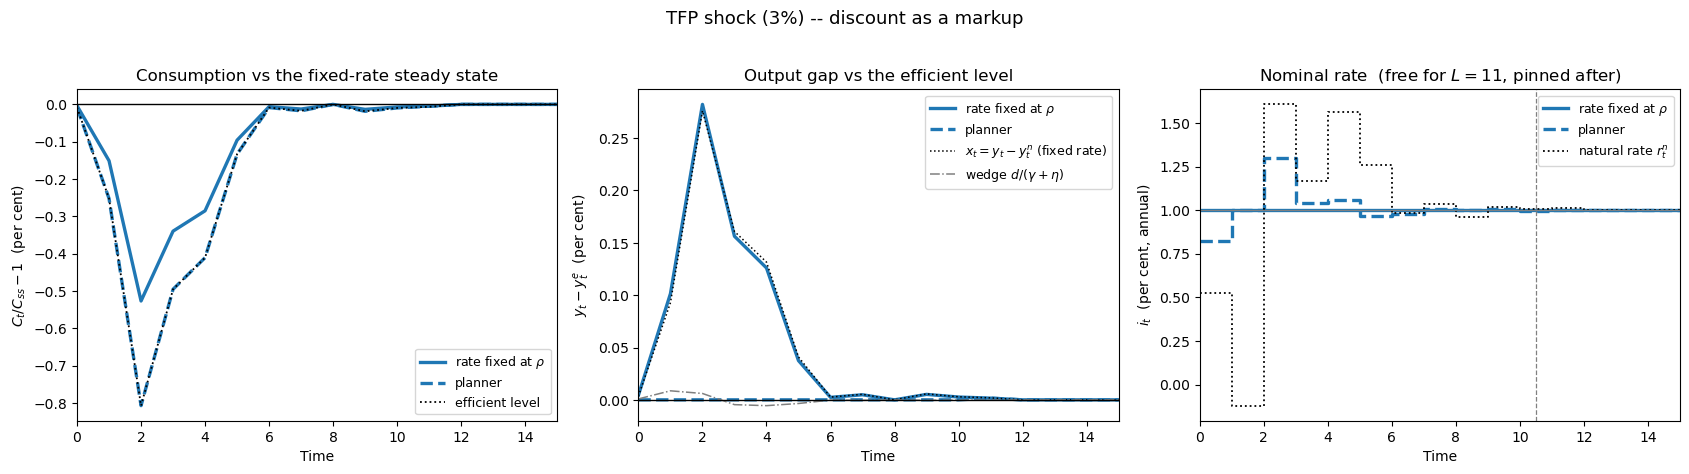

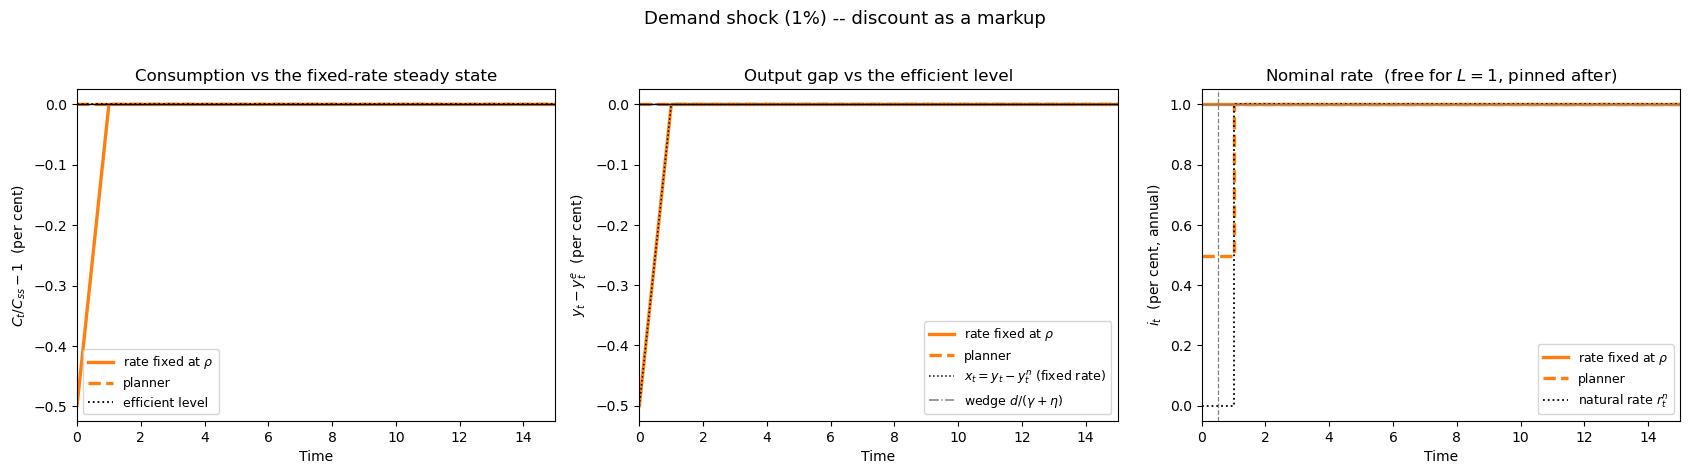

In [13]:
H = 16
COLOURS = {'TFP shock (3%)': 'C0', 'Demand shock (1%)': 'C1'}
FNAMES = {'TFP shock (3%)': '../semi_endo_markup_A.png',
          'Demand shock (1%)': '../semi_endo_markup_demand.png'}


def shock_figure(name, horizon=H):
    r_opt, s_opt, s_base = summary[name]
    col = COLOURS[name]
    t = np.arange(horizon)
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

    ax = axes[0]
    ax.plot(t, 100 * (np.exp(s_base['y'][:horizon]) - 1), color=col, lw=2.4,
            label=r'rate fixed at $\rho$')
    ax.plot(t, 100 * (np.exp(s_opt['y'][:horizon]) - 1), color=col, lw=2.4, ls='--',
            label='planner')
    ax.plot(t, 100 * (np.exp(s_opt['y_eff'][:horizon]) - 1), color='k', lw=1.3, ls=':',
            label='efficient level')
    ax.axhline(0, color='k', lw=1.0)
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$C_t/C_{ss}-1$  (per cent)')
    ax.set_title('Consumption vs the fixed-rate steady state')
    ax.legend(fontsize=9)

    ax = axes[1]
    ax.plot(t, 100 * (s_base['y'] - s_base['y_eff'])[:horizon], color=col, lw=2.4,
            label=r'rate fixed at $\rho$')
    ax.plot(t, 100 * (s_opt['y'] - s_opt['y_eff'])[:horizon], color=col, lw=2.4, ls='--',
            label='planner')
    ax.plot(t, 100 * s_base['x'][:horizon], color='k', lw=1.1, ls=':',
            label=r'$x_t=y_t-y^n_t$ (fixed rate)')
    ax.plot(t, 100 * (s_base['y_nat'] - s_base['y_eff'])[:horizon], color='grey', lw=1.1,
            ls='-.', label=r'wedge $d/(\gamma+\eta)$')
    ax.axhline(0, color='k', lw=1.0)
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$y_t-y^e_t$  (per cent)')
    ax.set_title('Output gap vs the efficient level')
    ax.legend(fontsize=9)

    ax = axes[2]
    ax.step(t, 100 * s_base['i'][:horizon], where='post', color=col, lw=2.4,
            label=r'rate fixed at $\rho$')
    ax.step(t, 100 * s_opt['i'][:horizon], where='post', color=col, lw=2.4, ls='--',
            label='planner')
    ax.step(t, 100 * s_base['r_nat'][:horizon], where='post', color='k', lw=1.3, ls=':',
            label=r'natural rate $r^n_t$')
    ax.axhline(100 * rho, color='grey', lw=0.9)
    ax.axvline(len(r_opt) - 0.5, color='grey', lw=0.9, ls='--')
    ax.set_xlim(0, horizon - 1)
    ax.set_xlabel('Time'); ax.set_ylabel(r'$i_t$  (per cent, annual)')
    ax.set_title(f'Nominal rate  (free for $L={len(r_opt)}$, pinned after)')
    ax.legend(fontsize=9)

    fig.suptitle(f'{name} -- discount as a markup', y=1.02, fontsize=13)
    fig.tight_layout()
    fig.savefig(FNAMES[name], dpi=150, bbox_inches='tight')
    plt.show()


for nm in CASES:
    shock_figure(nm)

## 8. Turning the dispersion channel back on

Everything above sets $\Lambda=Z$. With the exact $\Lambda$ the planner acquires a second,
genuinely real motive: markup dispersion across heterogeneous $\tau_i$ is a misallocation,
$\Lambda\le Z$ always, and cutting the rate compresses the dispersion — a Friedman-rule
motive. The legacy $y-d$ adjustment removed it (its own summary notes as much); under the
markup reading it comes back on its own.

It does not behave like the rest of the problem, and this section reports that rather than
smoothing it over.

In [14]:
print(f'{"rate path":<14}{"max log(Lam/Z)":>18}{"min log(Lam/Z)":>18}   (pp)')
print('-' * 54)
for lab, R in [('cut to 0', np.zeros(8)), ('flat at rho', np.ones(8) * rho),
               ('rho + 50bp', np.ones(8) * (rho + 0.005)), ('up to 4%', np.ones(8) * 0.04)]:
    s = solve(R, a_shock=True)
    lr = np.log(s['Lam'] / s['Z_t'])
    print(f'{lab:<14}{100*np.max(lr):>17.5f}p{100*np.min(lr):>17.5f}p')
print('\n-> Lambda <= Z everywhere, and the gap closes as i -> 0.  Dispersion is a real')
print('   misallocation and the planner can reduce it by cutting rates.\n')

print('escalation with the dispersion channel live:\n')
for name, kw in CASES.items():
    print(name)
    print(f'{"L":>3}{"objective":>21}{"peak|y-y_eff|":>16}{"last i":>10}{"a_phys vs base":>17}')
    base = solve(np.ones(3) * rho, **kw)
    for L in range(1, 11):
        best = None
        for seed in SEEDS:
            res = minimize(lambda v: -welfare(solve(v, **kw))[0], seed(L),
                           method='L-BFGS-B', bounds=[(0.0, 0.05)] * L,
                           options={'maxiter': 40000, 'ftol': 1e-20, 'gtol': 1e-16})
            if best is None or res.fun < best.fun:
                best = res
        s = solve(best.x, **kw)
        print(f'{L:>3}{best.fun:>21.12f}{np.max(np.abs(s["y"]-s["y_eff"])):>16.3e}'
              f'{best.x[-1]:>10.5f}{100*np.max(np.abs(s["a_phys"]-base["a_phys"])):>16.5f}p')
    print()
print('-> the objective is still improving at L = 10 and the rate is still drifting up.')
print('   This does NOT converge in the range tested, unlike sections 5-7.  The gain is')
print('   real (a_phys rises by up to ~0.03pp, worth more in utility than the observed')
print('   objective gain), but the horizon at which it settles has not been found.')

rate path         max log(Lam/Z)    min log(Lam/Z)   (pp)
------------------------------------------------------
cut to 0               -0.00343p         -0.05702p
flat at rho            -0.05454p         -0.05885p
rho + 50bp             -0.05648p         -0.11348p
up to 4%               -0.05697p         -0.63724p

-> Lambda <= Z everywhere, and the gap closes as i -> 0.  Dispersion is a real
   misallocation and the planner can reduce it by cutting rates.

escalation with the dispersion channel live:

TFP shock (3%)
  L            objective   peak|y-y_eff|    last i   a_phys vs base
  1      34.782640727933       2.822e-03   0.00992         0.00000p
  2      34.782609051669       2.822e-03   0.01444         0.00463p


  3      34.782426209214       5.560e-03   0.01814         0.01953p
  4      34.782238224505       6.503e-03   0.01732         0.02323p


  5      34.782092128996       7.346e-03   0.01845         0.02897p


  6      34.781996377665       8.321e-03   0.01852         0.02856p


  7      34.781903008229       9.479e-03   0.01952         0.02708p


...

  6      34.740322348849       7.447e-03   0.01809         0.02998p


  7      34.740173773158       8.612e-03   0.01905         0.02914p


  8      34.740040258949       9.549e-03   0.01974         0.02879p


  9      34.739916914204       1.027e-02   0.02029         0.02812p


 10      34.739815352034       1.087e-02   0.02072         0.02787p

-> the objective is still improving at L = 10 and the rate is still drifting up.
   This does NOT converge in the range tested, unlike sections 5-7.  The gain is
   real (a_phys rises by up to ~0.03pp, worth more in utility than the observed
   objective gain), but the horizon at which it settles has not been found.


## Summary

The firm's first-order condition makes $1/\text{disc}_i$ a markup, not a technology term, and
that single reclassification changes the model in three places.

1. **The wedge enters $y^n$ with coefficient $1/(\gamma+\eta)$, not $\varphi_{ya}$.** The
   planner family's "fold it into $\tilde a$, then subtract $d$" route nets out to $-1/4$
   where this gives $+1/4$: the right magnitude with the wrong sign. Section 3 checks both
   against a flex-price equilibrium built from the primitives, with $C$ and $N$ rebuilt from
   the firm-level allocations to machine precision. The markup form tracks it to
   $\le0.03$pp on every rate path tried; the legacy form is out by up to $1.2$pp — and on
   the aggressive-cut path it reports the wrong sign at $t=0$.

2. **The $y-d$ step disappears.** Output from the Euler equation is real consumption
   already. There is nothing left to strip out, so the "adjusted vs unadjusted welfare
   criterion" question the planner family had to resolve does not arise here.

3. **The error is invisible at a flat rate and large once policy moves.** $d$ is $0.03$pp
   when $i\equiv\rho$ and $2.4$pp on an aggressive cut. That is the worst possible place for
   a sign error, because moving the rate is precisely what the planner exercise does.

Independently of all of the above, the Dixit–Stiglitz price index is $1/\tilde A$, which the
old code already computed while using a different aggregate with both exponents flipped.
That fix is applied here and its effect is isolated in section 4.

**Two things are left open, and neither is resolved here.**

*Markup dispersion.* With the exact $\Lambda$ the planner gains a Friedman-rule motive —
$\Lambda\le Z$ always and cutting rates compresses the dispersion. Section 8 shows the
escalation then fails to converge within $L\le10$ and the rate drifts upward, so no optimal
horizon is reported for that case. Sections 5–7 therefore run with dispersion off. The
legacy notebooks did not face this because the $-d$ adjustment removed the motive; it is a
consequence of taking the markup reading seriously, and it needs its own treatment.

*Wages.* The nominal wage is the numeraire throughout, inherited from the rest of the repo,
so inflation is entirely movement in desired markups over a fixed wage. If wages move,
$\pi=-\Delta\log\tilde A$ picks up a $\Delta\log W$ term and section 4's inflation paths
change.